<a href="https://colab.research.google.com/github/ShAnFb82/IAD1/blob/main/IAD%20lab%202.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Початок. Частина 1**. Імпорт датасету drebin та завантаження даних

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report


df = pd.read_csv('drebin-215-dataset-5560malware-9476-benign.csv', low_memory=False)
print("Розмір датасету:", df.shape)
df.head()

Розмір датасету: (15036, 216)


,transact,onServiceConnected,bindService,attachInterface,ServiceConnection,android.os.Binder,SEND_SMS,Ljava.lang.Class.getCanonicalName,Ljava.lang.Class.getMethods,Ljava.lang.Class.cast,...,READ_CONTACTS,DEVICE_POWER,HARDWARE_TEST,ACCESS_WIFI_STATE,WRITE_EXTERNAL_STORAGE,ACCESS_FINE_LOCATION,SET_WALLPAPER_HINTS,SET_PREFERRED_APPLICATIONS,WRITE_SECURE_SETTINGS,class
0,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,S
1,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,S
2,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,S
3,0,0,0,0,0,0,0,0,0,1,...,0,0,0,1,1,1,0,0,0,S
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,S


# Очищуємо від невизначених характеристик

In [2]:
df.replace('?', np.nan, inplace=True)
df.dropna(inplace=True)

df['class'] = df['class'].map({'B': 0, 'S': 1})

X = df.drop('class', axis=1).astype(float)
y = df['class']

print("Розмір після очищення:", X.shape)
print("Розподіл класів:\n", y.value_counts())

Розмір після очищення: (15031, 215)
Розподіл класів:
 class
0    9476
1    5555
Name: count, dtype: int64


# Розділення даних на тренувальні та тестувальні

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (12024, 215)
X_test_scaled: (3007, 215)


# Базова модель

In [4]:
rf_before = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

start_time = time.time()
rf_before.fit(X_train_scaled, y_train)
time_before = time.time() - start_time

y_pred_before = rf_before.predict(X_test_scaled)
acc_before = accuracy_score(y_test, y_pred_before)
f1_before = f1_score(y_test, y_pred_before)

print(f"Кількість ознак (до PCA): {X_train_scaled.shape[1]}")
print(f"Час навчання: {time_before:.4f} сек")
print(f"Accuracy: {acc_before:.4f}")
print(f"F1-score: {f1_before:.4f}")

Кількість ознак (до PCA): 215
Час навчання: 2.4056 сек
Accuracy: 0.9877
F1-score: 0.9833


# Застосування PCA

Ознак до PCA: 215
Ознак після PCA (95% дисперсії): 151


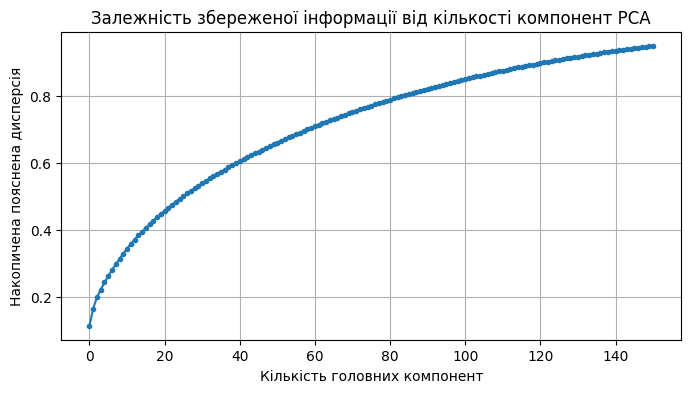

In [5]:
pca = PCA(n_components=0.95, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Ознак до PCA: {X_train_scaled.shape[1]}")
print(f"Ознак після PCA (95% дисперсії): {X_train_pca.shape[1]}")

plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', markersize=3)
plt.xlabel('Кількість головних компонент')
plt.ylabel('Накопичена пояснена дисперсія')
plt.title('Залежність збереженої інформації від кількості компонент PCA')
plt.grid(True)
plt.show()

# модель після PCA

In [6]:
rf_after = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

start_time = time.time()
rf_after.fit(X_train_pca, y_train)
time_after = time.time() - start_time

y_pred_after = rf_after.predict(X_test_pca)
acc_after = accuracy_score(y_test, y_pred_after)
f1_after = f1_score(y_test, y_pred_after)

comparison = pd.DataFrame({
    'Метрика': ['Кількість ознак', 'Час навчання (сек)', 'Accuracy', 'F1-score'],
    'До PCA': [X_train_scaled.shape[1], round(time_before, 4), round(acc_before, 4), round(f1_before, 4)],
    'Після PCA (95%)': [X_train_pca.shape[1], round(time_after, 4), round(acc_after, 4), round(f1_after, 4)]
})
comparison

,Метрика,До PCA,Після PCA (95%)
0,Кількість ознак,215.0000,151.0000
1,Час навчання (сек),2.4056,28.5440
2,Accuracy,0.9877,0.9794
3,F1-score,0.9833,0.9714


### **Короткий висновок:** Кількість ознак скоротилася з 215 до 151 (майже на 30%) при збереженні 95% дисперсії. Якість впала незначно. Замість прискорення час навчання зріс приблизно у 12 разів

# **Візуалізація за допомогою t-SNE**

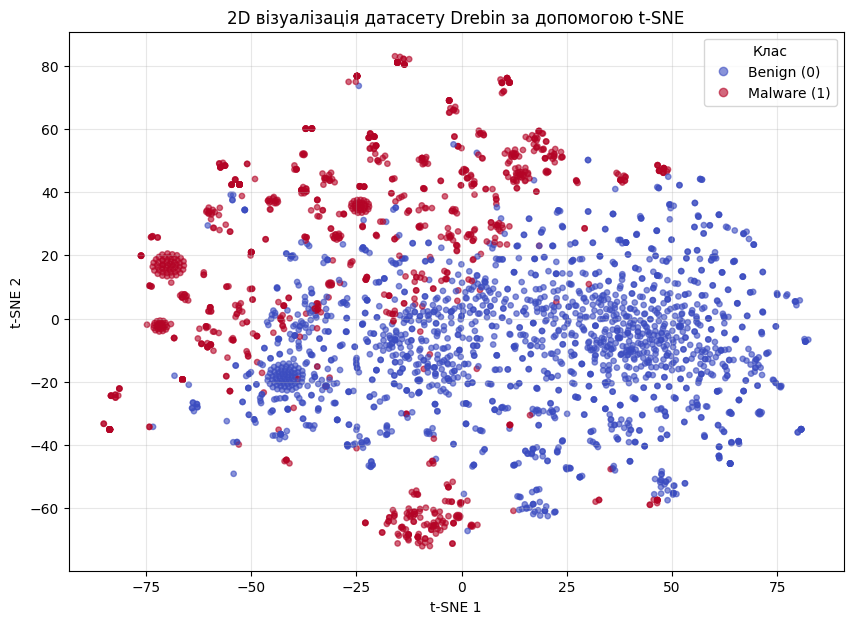

In [7]:
#Підвибірка на 3000 об'єктів зі збереженням пропорції класів щоб швидко
X_sample, _, y_sample, _ = train_test_split(
    X, y, train_size=3000, random_state=42, stratify=y
)
# Масштабування
X_sample_scaled = StandardScaler().fit_transform(X_sample)

# Застосовуємо t-SNE для стиснення 215 ознак до 2 координат (2D)
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_sample_scaled)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=y_sample, cmap='coolwarm', alpha=0.6, s=15
)
plt.legend(handles=scatter.legend_elements()[0], labels=['Benign (0)', 'Malware (1)'], title='Клас')
plt.title('2D візуалізація датасету Drebin за допомогою t-SNE')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.grid(True, alpha=0.3)
plt.show()

## Безпечні додатки (сині) формуються в центрі + справа, а шкідливі переважно зліва і зверху + трохи знизу.

# Вибір оптимальної кількості кластерів

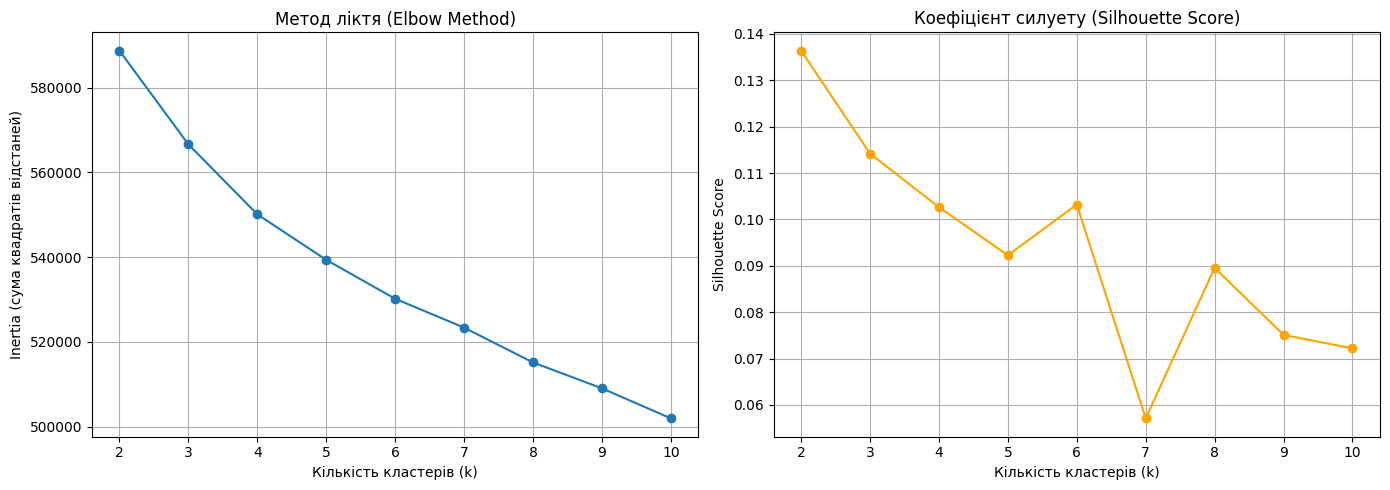

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Перевірка кількість кластерів k від 2 до 10
k_range = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_sample_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_sample_scaled, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Метод ліктя (Elbow Method)
ax1.plot(k_range, inertias, marker='o')
ax1.set_title('Метод ліктя (Elbow Method)')
ax1.set_xlabel('Кількість кластерів (k)')
ax1.set_ylabel('Inertia (сума квадратів відстаней)')
ax1.grid(True)

# 2. Коефіцієнт силуету (Silhouette Score)
ax2.plot(k_range, silhouette_scores, marker='o', color='orange')
ax2.set_title('Коефіцієнт силуету (Silhouette Score)')
ax2.set_xlabel('Кількість кластерів (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True)

plt.tight_layout()
plt.show()

### за методом ліктя інерція спадає плавно без різкого перегину що є типовим для даних високої розмірності. Коеф. силуету досягає абсолютного максимуму при k=2, а далі падає з невеликими підняттями. Через розмірність, і стається невисоке абсолютне значення силуету десь 0.137

# **Частина 2. К-means**

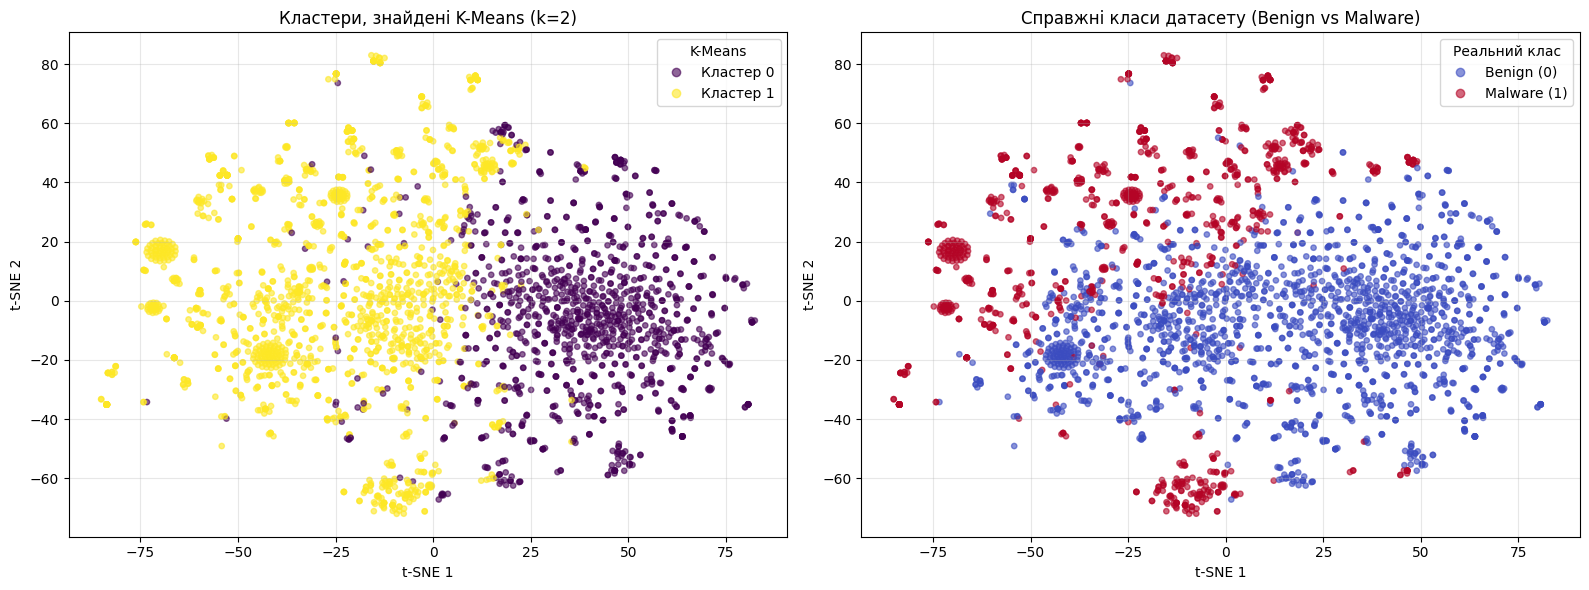

Таблиця відповідності кластерів і реальних класів:


"Реальний клас (0=B, 1=S)",0,1
Кластер K-Means,,
0,1126,102
1,765,1007


In [9]:
#Навчаємо K-Means з оптимальним k=2 )
kmeans_opt = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans_opt.fit_predict(X_sample_scaled)

#знайдені кластери vs реальні класи на координатах t-SNE
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# K-Means
sc1 = ax1.scatter(X_tsne[:, 0], X_tsne[:, 1], c=clusters, cmap='viridis', alpha=0.6, s=15)
ax1.legend(handles=sc1.legend_elements()[0], labels=['Кластер 0', 'Кластер 1'], title='K-Means')
ax1.set_title('Кластери, знайдені K-Means (k=2)')
ax1.set_xlabel('t-SNE 1')
ax1.set_ylabel('t-SNE 2')
ax1.grid(True, alpha=0.3)

#справжні класи
sc2 = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_sample, cmap='coolwarm', alpha=0.6, s=15)
ax2.legend(handles=sc2.legend_elements()[0], labels=['Benign (0)', 'Malware (1)'], title='Реальний клас')
ax2.set_title('Справжні класи датасету (Benign vs Malware)')
ax2.set_xlabel('t-SNE 1')
ax2.set_ylabel('t-SNE 2')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 3. Таблиця відповідності (скільки реальних класів потрапило в кожен кластер)
ct = pd.crosstab(
    pd.Series(clusters, name='Кластер K-Means'),
    pd.Series(y_sample.values, name='Реальний клас (0=B, 1=S)')
)
print("Таблиця відповідності кластерів і реальних класів:")
ct

### Фіолетивий кластер має 1128 безпечних і 102 шкідливих, а жовтий 1007 шкідливих + 765 безпечних. K-means не розпізнає вірус чи ні, а ділить додатки за схожістю, тому багато безпечних програм які мають багато різних дозволів були віднесені ближче до malware.

# **Частина 3. Обробка та класифікація текстових даних NLP**

## Для наступного завдання було обрано наступний датасет - https://www.kaggle.com/datasets/team-ai/spam-text-message-classification?resource=download

In [11]:
df_text = pd.read_csv('SPAM text message 20170820 - Data.csv')

print("Розмір датасету:", df_text.shape)
print("\nПропущені значення:\n", df_text.isnull().sum())
print("\nРозподіл класів:\n", df_text['Category'].value_counts())
df_text.head()

Розмір датасету: (5572, 2)

Пропущені значення:
 Category    0
Message     0
dtype: int64

Розподіл класів:
 Category
ham     4825
spam     747
Name: count, dtype: int64


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## В датасеті 5572 повідомлення, категорії ham та spam. Очищуємо від зайвого:

In [12]:
import re
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

# Завантажуємо список англійських стоп-слів (the, is, at, which, on тощо)
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = text.split()
    words = [w for w in words if w not in stop_words and len(w) > 1]
    return ' '.join(words)

df_text['clean_message'] = df_text['Message'].apply(clean_text)

#Різниця "до" і "після" на перших 3 рядках
df_text[['Category', 'Message', 'clean_message']].head(3)

,Category,Message,clean_message
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis great wo...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...


# Візуалізуємо WordCloud для ham та spam

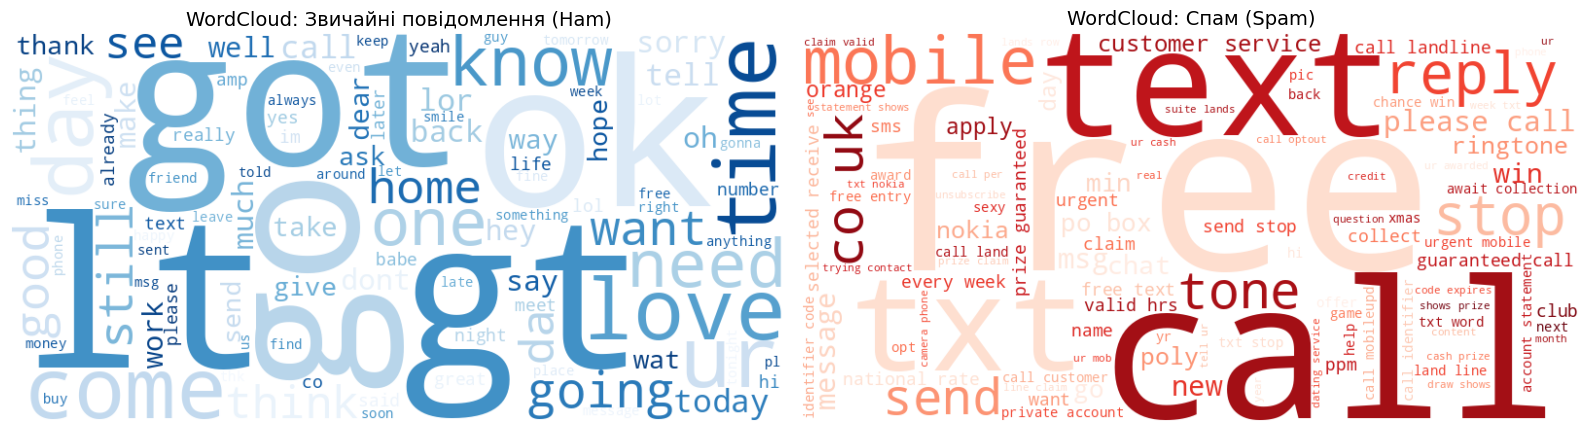

In [13]:
# Збираємо всі очищені тексти в один великий рядок для кожного класу
ham_text = ' '.join(df_text[df_text['Category'] == 'ham']['clean_message'])
spam_text = ' '.join(df_text[df_text['Category'] == 'spam']['clean_message'])

#WordCloud
wc_ham = WordCloud(width=800, height=400, background_color='white', colormap='Blues', max_words=100).generate(ham_text)
wc_spam = WordCloud(width=800, height=400, background_color='white', colormap='Reds', max_words=100).generate(spam_text)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.imshow(wc_ham, interpolation='bilinear')
ax1.axis('off')
ax1.set_title('WordCloud: Звичайні повідомлення (Ham)', fontsize=14)

ax2.imshow(wc_spam, interpolation='bilinear')
ax2.axis('off')
ax2.set_title('WordCloud: Спам (Spam)', fontsize=14)

plt.tight_layout()
plt.show()

## ham - переважють слова типу go, ok, got6 home - тощо. В Спамі - free, call. text, mobile, stop - і тд. Загалом словники двох класів майже не перетинаються за ключовими словами тому класифікація повинна мати високу точність.

# Векторизація та класифікація текстів

Розмірність матриці TF-IDF (train): (4457, 3000)

Classification Report:
              precision    recall  f1-score   support

     Ham (0)       0.97      1.00      0.98       966
    Spam (1)       1.00      0.79      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.93      1115
weighted avg       0.97      0.97      0.97      1115



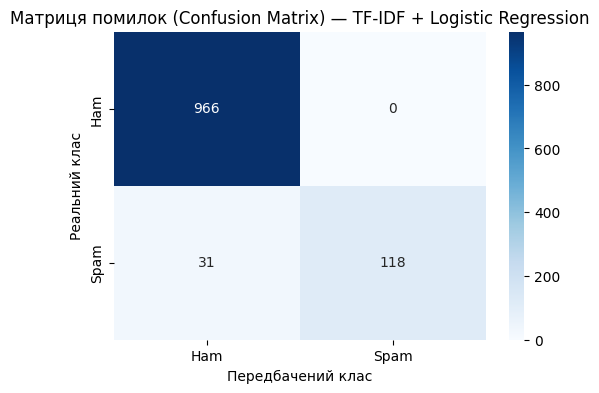

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

X_txt = df_text['clean_message']
y_txt = df_text['Category'].map({'ham': 0, 'spam': 1})

# Розділ на тренувальні та тестувальні зі збереженням пропорції класів
X_train_txt, X_test_txt, y_train_txt, y_test_txt = train_test_split(
    X_txt, y_txt, test_size=0.2, random_state=42, stratify=y_txt
)

# 3. Векторизація TF-IDF (3000 найважливіших)
tfidf = TfidfVectorizer(max_features=3000)
X_train_tfidf = tfidf.fit_transform(X_train_txt)
X_test_tfidf = tfidf.transform(X_test_txt)

print("Розмірність матриці TF-IDF (train):", X_train_tfidf.shape)

# 4. Навчання логістичної регресії
clf = LogisticRegression(random_state=42, max_iter=1000)
clf.fit(X_train_tfidf, y_train_txt)

# 5. Робимо прогноз і виводимо метрики
y_pred_txt = clf.predict(X_test_tfidf)

print("\nClassification Report:")
print(classification_report(y_test_txt, y_pred_txt, target_names=['Ham (0)', 'Spam (1)']))

#Confusion Matrix
cm = confusion_matrix(y_test_txt, y_pred_txt)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.xlabel('Передбачений клас')
plt.ylabel('Реальний клас')
plt.title('Матриця помилок (Confusion Matrix) — TF-IDF + Logistic Regression')
plt.show()

## Підсумок -загальна точність - 97%, F1 - 0.88 для спаму. Вийшло дивним чином 0 хибних спрацювань (я думав що можливі все ж поодинокі помилки) для звичайних нешкідливих повідомлень. Спаму пропустив він 31 повідомлення, таким чином правильно виявила 118 . Це скоріше за все через дисбаланс класів.